# 100-year block-centroid tangent alignment — years, layer 4

Compare saved **KMeans+PCA** and **MFA-EM (HDDC)** checkpoints at rank thresholds $\tau\in\{0.1,0.01\}$, for both available component counts $K\in\{50,100\}$.

The reference point for each 100-year block is the centroid of **all held-out prompts in that block**, across templates:
$$\mu_b=\frac{1}{N_b}\sum_{i:b\le y_i<b+100}x_i,\qquad t_b=\frac{\mu_{b+100}-\mu_b}{\|\mu_{b+100}-\mu_b\|}.$$
Blocks are zero-anchored: **1000–1099, 1100–1199, …**. All prompts in a block have equal weight; years are not weighted equally. Secants connect successive blocks. Partial blocks are retained; empty blocks are not bridged. In the weight formula, conditioning on a block means using every prompt in that block. Component weights use **all held-out prompts in each endpoint block**, with each block contributing half the weight:
$$w_{b,k}=\tfrac12\Pr(k\mid b)+\tfrac12\Pr(k\mid b+100),\qquad s_b=\sum_k w_{b,k}(t_b^\top v_{k,1})^2.$$
The reported primary score averages $s_b$ equally across valid segments. Undefined PC1s contribute zero while retaining their weight; the conditional score normalizes by pooled identifiable weight.

**Run:** select the repository `.venv` Python kernel, edit the next configuration cell, then **Run All**. The notebook imports the evaluator in `scripts/temporary/evaluate_year_tangent_alignment.py`. Centroid and secant computation stays in the analysis module; this notebook displays the returned geometry. No training is performed. The legacy `TEMPLATE_ID` argument is ignored by centroid evaluation.

**Evaluation space:** centroids, secants, assignments, and alignment scores use the original 4096-dimensional activation space. The shuffled control uses this same space. PCA is fitted once on all test activations solely for the 3D visualization; the Gaussian colors and hover scores still report original-space alignment.

In [1]:
from pathlib import Path
import sys
import os
import gc
import json
import time
from datetime import datetime, timezone

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/dalg").is_dir() and (p / "pyproject.toml").is_file())
for folder in (REPO / "src", REPO / "scripts/temporary"):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import evaluate_year_tangent_alignment as evaluator
from evaluate_sae_label_tangents import comparison_plan
from dalg.analysis.label_tangent_alignment import estimate_label_tangents
from dalg.analysis.activation_projection import fit_activation_pca, project_alignment_inputs, project_gaussian_components
from plot_label_tangent_alignment import make_alignment_figure

%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
# Edit these parameters, then rerun all cells.
DATA_ROOT = REPO / "dalg-cache/sae-manifold/sae_manifold_years_neutral_llama31_8b_last"
LAYER = 4
TAUS = [0.1, 0.01]           # Saved surgery_threshold values, not evaluation-time rank changes.
K_VALUES = [50, 100]        # Use [50] or [100] to evaluate just one component count.
TEMPLATE_ID = "3"          # Compatibility argument; ignored by centroid evaluation.
DEVICE = "cpu"            # Set to "cuda" only inside an appropriate GPU allocation.
BATCH_SIZE = 256
THREADS = 8
SEED = 42
ATOL, RTOL = 1e-12, 1e-10
PCA_COMPONENTS = 3        # Visualization only; evaluation uses all activation dimensions.
OUTPUT_BASE = REPO / "outputs/experiments/year_centroid_alignment_original_space"

torch.set_num_threads(min(THREADS, len(os.sched_getaffinity(0))))
TEST_DIR = DATA_ROOT / "test"
COLORS = {"hddc": "#b34b38", "kmeans": "#236e9f"}
METHOD_NAMES = {"hddc": "HDDC-EM", "kmeans": "KMeans+PCA"}

## Select the saved runs

Selection uses checkpoint configuration values, not filename guesses. The regular `*_hddc_em` and `*_kmeans_pca` experiment folders are paired by layer, K, and threshold; the separately named `q1...SKIP` experiment is not included. Every requested pair must exist.

In [3]:
plan = [item for item in comparison_plan([DATA_ROOT])
        if item["layer"] == LAYER and item["K"] in K_VALUES and item["threshold"] in TAUS]
expected = {(k, tau) for k in K_VALUES for tau in TAUS}
assert {(p["K"], p["threshold"]) for p in plan} == expected, "Missing requested saved model pair"
assert len(plan) == len(expected), "Ambiguous model selection"
plan.sort(key=lambda p: (K_VALUES.index(p["K"]), TAUS.index(p["threshold"])))
plan_table = pd.DataFrame(plan)[["name", "layer", "K", "threshold", "kmeans_run", "hddc_run"]]
display(plan_table.rename(columns={"threshold": "tau"}))

,name,layer,K,tau,kmeans_run,hddc_run
0,years_l04_k50_threshold0.1,4,50,0.10,/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cac...,/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cac...
1,years_l04_k50_threshold0.01,4,50,0.01,/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cac...,/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cac...
2,years_l04_k100_threshold0.1,4,100,0.10,/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cac...,/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cac...
3,years_l04_k100_threshold0.01,4,100,0.01,/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cac...,/orfeo/cephfs/scratch/dssc/zenocosini/dalg-cac...


## Inspect held-out block coverage

All held-out prompts contribute to their 100-year block centroid and assignment weights. The table shows block boundaries, actual centroid endpoints, and prompt counts. Missing individual years within a block are allowed. Partial blocks are retained; empty blocks are not bridged. Centroid coordinates in the table are PCA3 display coordinates; the evaluator uses full-dimensional centroids.

In [4]:
first = plan[0]
inputs = evaluator.load_inputs(Path(first["kmeans_run"]), Path(first["hddc_run"]),
                               TEST_DIR, BATCH_SIZE, label_field="year")

## Prepare PCA for visualization only

Fit one centered PCA to all test activations for the 3D display. This basis is shared by every model pair. Centroids and secants are computed in the original activation space; their coordinates are projected only for display. PCA does not change evaluation scores or component eligibility.

In [5]:
projection = fit_activation_pca(inputs["activations"], n_components=PCA_COMPONENTS)
projected_activations, _ = project_alignment_inputs(inputs["activations"], {}, projection)
print(f"Visualization PCA: {projection['input_dimension']} -> {projection['dimension']} dimensions")
print(f"Retained variance: {projection['retained_variance_fraction']:.2%}")
display(pd.DataFrame({"PC": range(1, PCA_COMPONENTS + 1),
                      "explained_variance_ratio": projection["explained_variance_ratio"].tolist()}))

Visualization PCA: 4096 -> 3 dimensions
Retained variance: 18.95%


,PC,explained_variance_ratio
0,1,0.104573
1,2,0.054700
2,3,0.030202


,test_prompts,example_prompt
template_id,,
0,227,The year is 1001
1,188,"According to this record, the year is 1003"
10,202,"As indicated here, the year is 1000"
11,195,"As stated in this entry, the year is 1001"
12,212,The record indicates that the year is 1000
13,164,The entry indicates that the year is 1003
14,193,The notation indicates that the year is 1005
15,209,"For this record, the year is 1000"
16,202,"According to the calendar, the year is 1014"


Test data: 4,004 prompts, 11 block centroids
All-template block centroids: 10 valid secants
Exclusions: {'missing_next_year': 0, 'insufficient_samples': 0, 'degenerate_difference': 0}


,first_block_start,first_block_end,second_block_start,second_block_end,start_count,end_count,start_centroid_display_pca3,end_centroid_display_pca3
0,1000,1099,1100,1199,414,362,"[-1.0031601462275912, 0.8522075163223921, -0.4...","[-1.0276480603792761, 0.5218848190961713, -0.0..."
1,1100,1199,1200,1299,362,403,"[-1.0276480603792761, 0.5218848190961713, -0.0...","[-0.8779382578906483, 0.09873668741177893, 0.2..."
2,1200,1299,1300,1399,403,383,"[-0.8779382578906483, 0.09873668741177893, 0.2...","[-0.5701096663343828, -0.24526820988072096, 0...."
3,1300,1399,1400,1499,383,415,"[-0.5701096663343828, -0.24526820988072096, 0....","[-0.38846503410076605, -0.510471728852871, 0.4..."
4,1400,1499,1500,1599,415,415,"[-0.38846503410076605, -0.510471728852871, 0.4...","[0.022298621822394612, -0.6663785308229142, 0...."
5,1500,1599,1600,1699,415,389,"[0.022298621822394612, -0.6663785308229142, 0....","[0.39751345510892167, -0.7662529191619839, -0...."
6,1600,1699,1700,1799,389,411,"[0.39751345510892167, -0.7662529191619839, -0....","[0.7284139899348367, -0.4863353833990535, -0.4..."
7,1700,1799,1800,1899,411,386,"[0.7284139899348367, -0.4863353833990535, -0.4...","[1.1285995439320602, 0.18706984679381108, -0.2..."


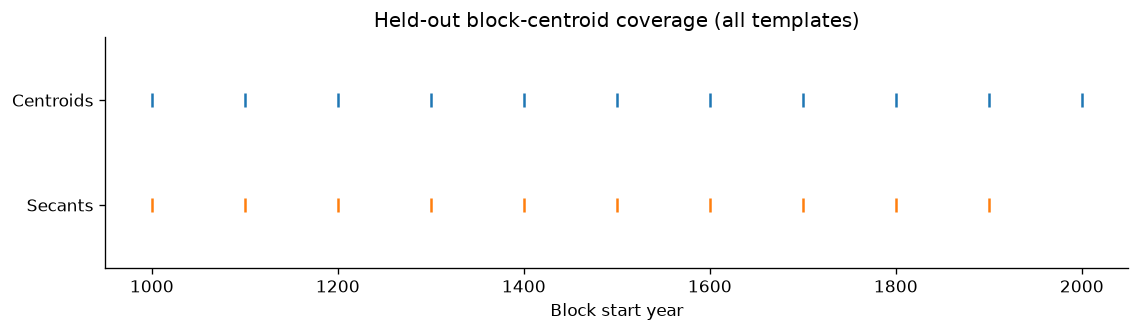

In [6]:
records = inputs["records"]
prompt_table = pd.DataFrame({
    "year": inputs["years"].tolist(), "template_id": inputs["templates"],
    "prompt": [r["prompt"] for r in records],
})
templates_table = (prompt_table.groupby("template_id", sort=True)
                   .agg(test_prompts=("year", "size"), example_prompt=("prompt", "first")))
display(templates_table)
reference = estimate_label_tangents(inputs["activations"], inputs["years"], inputs["templates"],
                                    template_id=TEMPLATE_ID, atol=ATOL, rtol=RTOL)
# Project the evaluated centroids without rebuilding or filtering the secants.
plot_reference = {key: reference[key] for key in ("years", "counts", "block_size", "endpoint_indices", "segment_years")}
plot_reference["means"], _ = project_alignment_inputs(reference["means"], {}, projection)
EVALUATION_DIMENSION = inputs["activations"].shape[1]
assert reference["tangents"].shape[1] == EVALUATION_DIMENSION
assert len(reference["segment_years"]), "No valid successive-block centroid pairs"
print(f"Test data: {len(records):,} prompts, {len(reference['years']):,} block centroids")
print(f"All-template block centroids: {len(reference['segment_years'])} valid secants")
print("Exclusions:", reference["exclusions"])
endpoint_indices = reference["endpoint_indices"].tolist()
display(pd.DataFrame([
    {"first_block_start": int(reference["years"][a]),
     "first_block_end": int(reference["years"][a]) + reference["block_size"] - 1,
     "second_block_start": int(reference["years"][b]),
     "second_block_end": int(reference["years"][b]) + reference["block_size"] - 1,
     "start_count": int(reference["counts"][a]), "end_count": int(reference["counts"][b]),
     "start_centroid_display_pca3": plot_reference["means"][a].tolist(),
     "end_centroid_display_pca3": plot_reference["means"][b].tolist()}
    for a, b in endpoint_indices
]).head(8))
fig, ax = plt.subplots(figsize=(11, 2.5))
ax.scatter(reference["years"], np.ones(len(reference["years"])), marker="|", s=70,
           label="Block centroid")
ax.scatter(reference["segment_years"], np.zeros(len(endpoint_indices)), marker="|", s=70,
           label="Valid successive-block segment start")
ax.set(xlabel="Block start year", yticks=[0, 1], yticklabels=["Secants", "Centroids"], ylim=(-0.6, 1.6),
       title="Held-out block-centroid coverage (all templates)")
plt.show()

## Run the evaluation

Each pair uses the same block-centroid secants and all prompts in both endpoint blocks for weights. The shuffled control permutes labels across **all held-out prompts**, then recomputes block centroids; evaluation labels and assignments stay fixed. Real-versus-control comparisons use their shared valid segments.

This evaluation uses one reference population, so cross-fit reference agreement is not defined. The shuffle is one control realization, not a significance test. The legacy `evaluate_template_alignment` entrypoint calls the centroid method and ignores template selection.

This cell reruns the requested comparisons and creates a new output directory on each execution. Detailed JSON reports retain block counts, centroid endpoint indices, exclusions, component diagnostics, and source provenance.

Pass raw activations and original model PC1s directly to the evaluator. Afterwards, project geometry for display while retaining the original-space component scores and eligibility. A direction with a vanishing display projection has no visible line, but keeps its original evaluation score. The saved PCA artifact describes visualization only.

In [7]:
RUN_DIR = OUTPUT_BASE / (
    f"layer{LAYER:02d}_original_space_block{reference['block_size']}_centroids_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ"))
RUN_DIR.mkdir(parents=True, exist_ok=False)
settings = dict(layer=LAYER, taus=TAUS, K_values=K_VALUES, reference_kind="block_centroids", block_size=reference["block_size"],
                device=DEVICE, batch_size=BATCH_SIZE, threads=torch.get_num_threads(),
                seed=SEED, atol=ATOL, rtol=RTOL, data_root=str(DATA_ROOT.resolve()),
                evaluation_population="all held-out endpoint-block prompts", comparisons=plan,
                evaluation_space="raw fitted shard space", evaluation_dimension=EVALUATION_DIMENSION,
                visualization_projection=evaluator._jsonable({k: v for k, v in projection.items() if k not in ("mean", "basis")}),
                visualization_pca_fitting_population="all test activations")
(RUN_DIR / "comparison_plan.json").write_text(json.dumps(settings, indent=2) + "\n")
torch.save(projection, RUN_DIR / "visualization_pca_projection.pt")
reports = {}
plot_comparisons = {}
summary_rows, segment_rows = [], []
for i, item in enumerate(plan):
    started = time.monotonic()
    print(f"[{i + 1}/{len(plan)}] layer={LAYER}, K={item['K']}, tau={item['threshold']:g}", flush=True)
    # The first load above is reused; later pairs run the same provenance checks.
    if i > 0 or "inputs" not in globals():
        inputs = evaluator.load_inputs(Path(item["kmeans_run"]), Path(item["hddc_run"]),
                                       TEST_DIR, BATCH_SIZE, label_field="year")
    geometry = evaluator.model_geometry_and_assignments(inputs["models"], inputs["activations"],
                                                        DEVICE, BATCH_SIZE)
    assert all(g["pc1"].shape[1] == EVALUATION_DIMENSION for g in geometry.values())
    report = evaluator.evaluate_template_alignment(
        inputs["activations"], inputs["years"], inputs["templates"], geometry,
        template_id=TEMPLATE_ID, seed=SEED, atol=ATOL, rtol=RTOL)
    assert torch.equal(report["segment_years"], reference["segment_years"])
    report["provenance"] = dict(inputs["provenance"],
                                representation="raw fitted shard space", evaluation_dimension=EVALUATION_DIMENSION,
                                assignment_representation="raw fitted shard space")
    # Display projection never enters the evaluator or its component diagnostics.
    _, display_geometry = project_alignment_inputs(inputs["activations"], geometry, projection)
    report["visualization_projection"] = dict(settings["visualization_projection"],
        fitting_population="all test activations", purpose="display only",
        artifact="visualization_pca_projection.pt",
        pc1_projection_squared_norm={kind: g["pc1_projection_squared_norm"] for kind, g in display_geometry.items()})
    report["prompt_distribution"] = evaluator.prompt_distribution(
        inputs["records"], report["fold_rows"], inputs["years"])
    reports[item["name"]] = report
    for kind in ("hddc", "kmeans"):
        label = f"{METHOD_NAMES[kind]} | K={item['K']} | tau={item['threshold']:g}"
        plot_comparisons[label] = dict(
            gaussians=project_gaussian_components(inputs["models"][kind], kind, projection),
            components=report["methods"][kind]["folds"][0]["components"],
            pc1=display_geometry[kind]["pc1"],
            pc1_visible=display_geometry[kind]["identifiable"])
    (RUN_DIR / f"{item['name']}.json").write_text(
        json.dumps(evaluator._jsonable(report), indent=2, allow_nan=False) + "\n")
    for kind, result in report["methods"].items():
        summary_rows.append(dict(
            name=item["name"], layer=LAYER, K=item["K"], tau=item["threshold"], method=kind,
            reference_kind="block_centroids", block_size=reference["block_size"],
            evaluation_space="raw fitted shard space", evaluation_dimension=EVALUATION_DIMENSION, segments=len(report["segment_years"]),
            control_segments=len(report["negative_control"]["segment_years"]),
            **{key: result[key] for key in ("score", "conditional_score", "unidentified_weight",
                "eligible_component_fraction", "negative_control_score", "matched_real_score")}))
    for j, year in enumerate(report["segment_years"].tolist()):
        h = float(report["methods"]["hddc"]["segment_scores"][j])
        k = float(report["methods"]["kmeans"]["segment_scores"][j])
        segment_rows.append(dict(name=item["name"], K=item["K"], tau=item["threshold"],
                                 year=year, hddc=h, kmeans=k, difference=h-k))
    print(f"  {len(report['segment_years'])} segments; "
          f"HDDC={report['methods']['hddc']['score']:.6f}, "
          f"KMeans={report['methods']['kmeans']['score']:.6f}; "
          f"{time.monotonic() - started:.1f}s", flush=True)
    del inputs, geometry, display_geometry
    gc.collect()
summary = pd.DataFrame(summary_rows)
segments = pd.DataFrame(segment_rows)
summary.to_csv(RUN_DIR / "summary.csv", index=False)
segments.to_csv(RUN_DIR / "segments.csv", index=False)
print("Saved results:", RUN_DIR)
display(summary[["K", "tau", "method", "segments", "score", "conditional_score",
                 "unidentified_weight", "negative_control_score", "matched_real_score"]])

[1/4] layer=4, K=50, tau=0.1
  10 segments; HDDC=0.092130, KMeans=0.044836; 4.3s
[2/4] layer=4, K=50, tau=0.01
  10 segments; HDDC=0.083363, KMeans=0.044836; 6.2s
[3/4] layer=4, K=100, tau=0.1
  10 segments; HDDC=0.050215, KMeans=0.044949; 9.9s
[4/4] layer=4, K=100, tau=0.01
  10 segments; HDDC=0.049402, KMeans=0.044949; 9.2s
Saved results: /orfeo/cephfs/home/dssc/zenocosini/decomposing-activations-local-geometry/outputs/experiments/year_centroid_alignment_original_space/layer04_original_space_block100_centroids_20261111T140211_444543Z


,K,tau,method,segments,score,conditional_score,unidentified_weight,negative_control_score,matched_real_score
0,50,0.10,kmeans,10,0.044836,0.044836,4.440892e-17,0.009252,0.044836
1,50,0.10,hddc,10,0.092130,0.092130,1.110223e-17,0.014930,0.092130
2,50,0.01,kmeans,10,0.044836,0.044836,4.440892e-17,0.009252,0.044836
3,50,0.01,hddc,10,0.083363,0.083363,1.110223e-17,0.014829,0.083363
4,100,0.10,kmeans,10,0.044949,0.044949,1.110223e-17,0.006126,0.044949
5,100,0.10,hddc,10,0.050215,0.050215,1.110223e-17,0.012954,0.050215
6,100,0.01,kmeans,10,0.044949,0.044949,1.110223e-17,0.006126,0.044949
7,100,0.01,hddc,10,0.049402,0.049402,1.110223e-17,0.013373,0.049402


## Mean alignment and shuffled control

The left panels show the primary score. The right panels compare real and shuffled references on the same control-eligible segments. Solid bars are real; hatched bars are shuffled. Scores are squared directional alignments, averaged using the weights above.

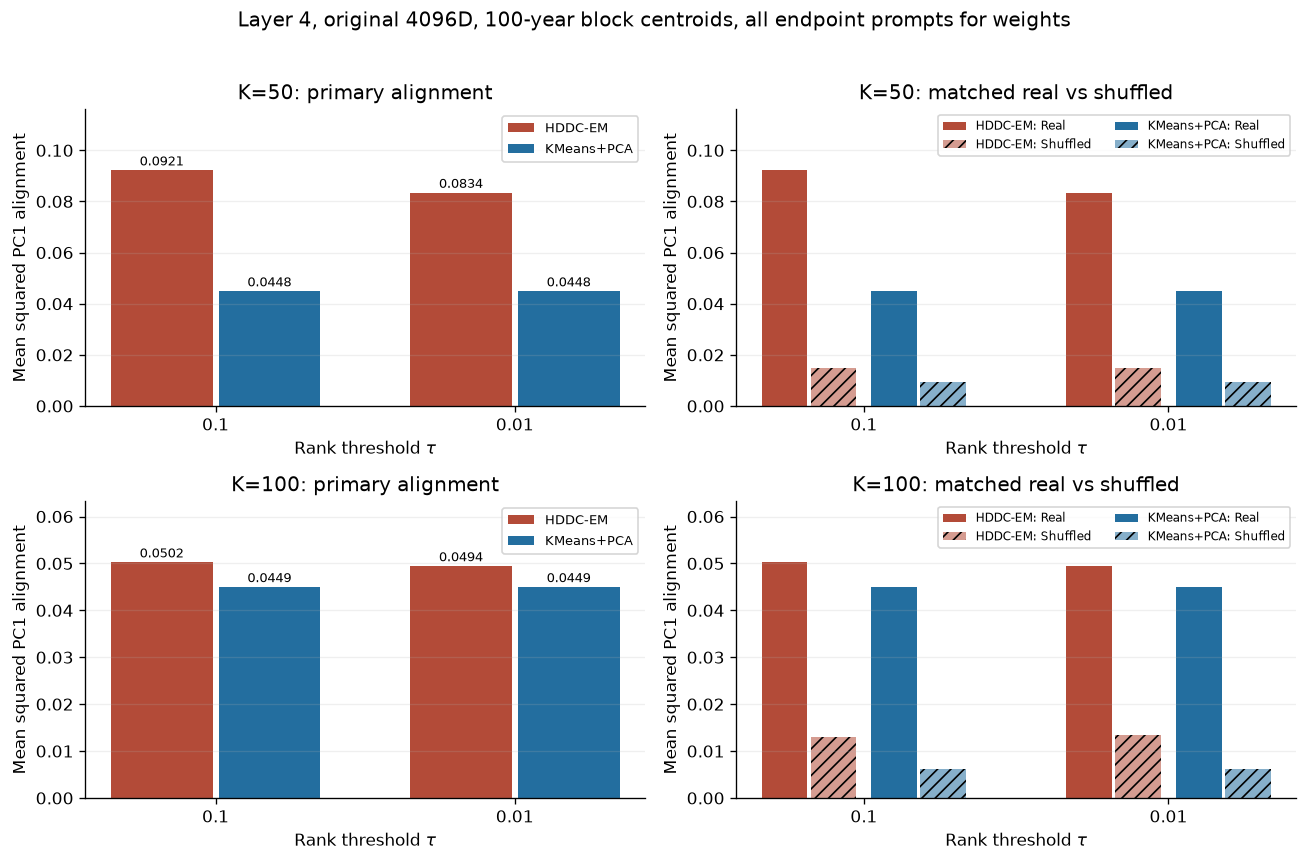

In [8]:
fig, axes = plt.subplots(len(K_VALUES), 2, figsize=(11, 3.5 * len(K_VALUES)), squeeze=False)
x = np.arange(len(TAUS))
for row, k in enumerate(K_VALUES):
    ax, control_ax = axes[row]
    for offset, kind in enumerate(("hddc", "kmeans")):
        table = summary[(summary.K == k) & (summary.method == kind)].set_index("tau").loc[TAUS]
        centers = x + (offset - 0.5) * 0.36
        ax.bar(centers, table.score, width=0.34, color=COLORS[kind], label=METHOD_NAMES[kind])
        for center, score in zip(centers, table.score):
            ax.annotate(f"{score:.4f}", (center, score), xytext=(0, 3), textcoords="offset points",
                        ha="center", fontsize=8)
        for shift, field, hatch, alpha, label in (
            (-0.08, "matched_real_score", "", 1., "Real"),
            (0.08, "negative_control_score", "///", 0.55, "Shuffled"),
        ):
            control_ax.bar(centers + shift, table[field], width=0.15,
                           color=COLORS[kind], hatch=hatch, alpha=alpha,
                           label=f"{METHOD_NAMES[kind]}: {label}")
    for axis in (ax, control_ax):
        axis.set(xticks=x, xticklabels=[f"{tau:g}" for tau in TAUS], xlabel=r"Rank threshold $\tau$",
                 ylabel="Mean squared PC1 alignment")
        axis.set_ylim(0, axis.get_ylim()[1] * 1.2)
        axis.grid(axis="y", alpha=.2)
    ax.set_title(f"K={k}: primary alignment")
    control_ax.set_title(f"K={k}: matched real vs shuffled")
    ax.legend(fontsize=8)
    control_ax.legend(fontsize=7, ncols=2)
fig.suptitle(f"Layer {LAYER}, original {EVALUATION_DIMENSION}D, 100-year block centroids, all endpoint prompts for weights", y=1.02)
fig.tight_layout()
fig.savefig(RUN_DIR / "mean_alignment.png", dpi=180, bbox_inches="tight")
fig.savefig(RUN_DIR / "mean_alignment.pdf", bbox_inches="tight")
plt.show()

## Alignment along the block axis

Points show only observed valid segments; lines are omitted so empty blocks remain visible. Each column uses the same vertical scale.

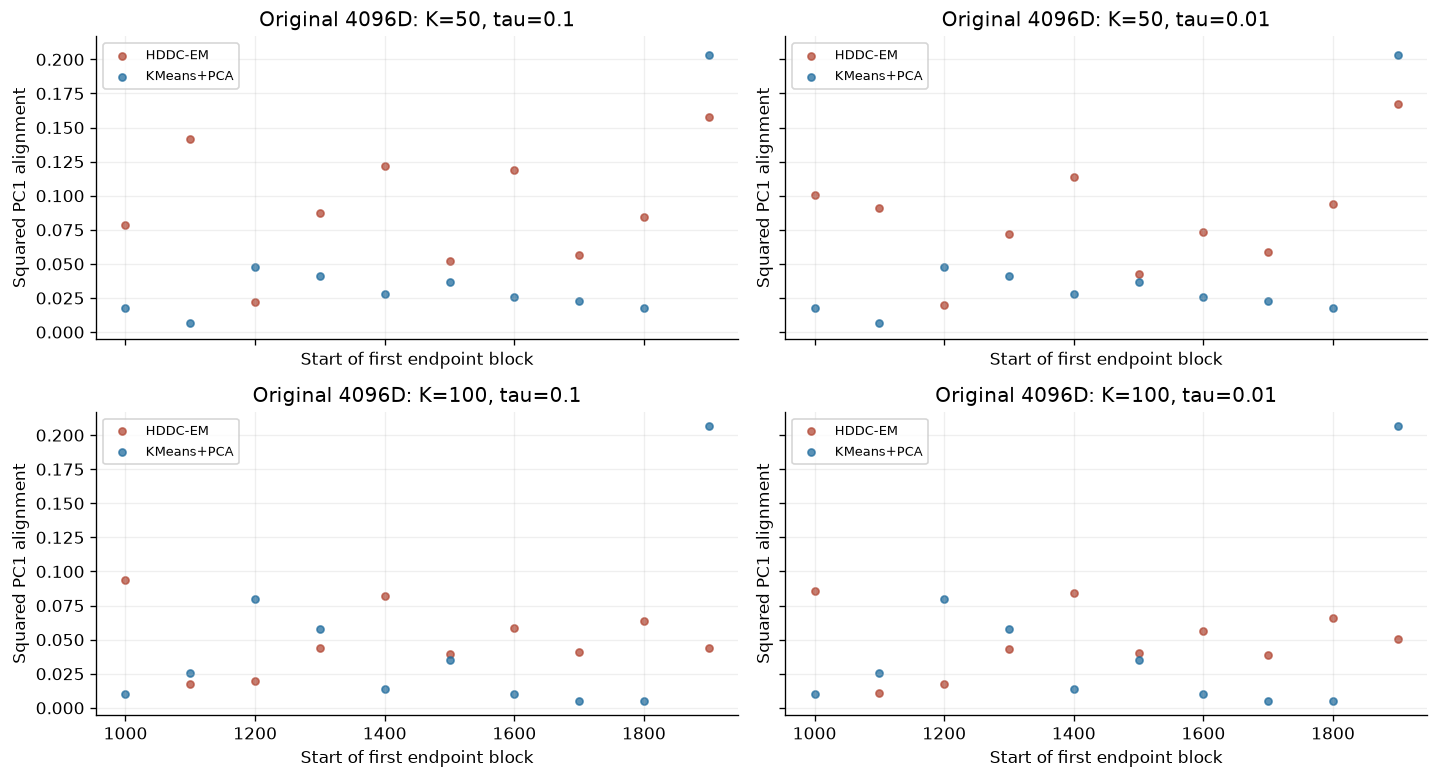

In [9]:
fig, axes = plt.subplots(len(K_VALUES), len(TAUS), figsize=(12, 3.3 * len(K_VALUES)),
                         squeeze=False, sharex=True, sharey=True)
for i, k in enumerate(K_VALUES):
    for j, tau in enumerate(TAUS):
        ax = axes[i, j]
        table = segments[(segments.K == k) & (segments.tau == tau)]
        for kind in ("hddc", "kmeans"):
            ax.scatter(table.year, table[kind], s=18, alpha=.75,
                       color=COLORS[kind], label=METHOD_NAMES[kind])
        ax.set(title=f"Original {EVALUATION_DIMENSION}D: K={k}, tau={tau:g}", xlabel="Start of first endpoint block", ylabel="Squared PC1 alignment")
        ax.grid(alpha=.2)
        ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RUN_DIR / "alignment_by_year.png", dpi=180)
fig.savefig(RUN_DIR / "alignment_by_year.pdf")
plt.show()

## Paired differences

Positive differences favor HDDC; negative differences favor KMeans+PCA. The zero line marks equal alignment. The summary below gives the mean difference and the fraction of segments with higher HDDC alignment, without treating dependent segments as independent statistical replicates.

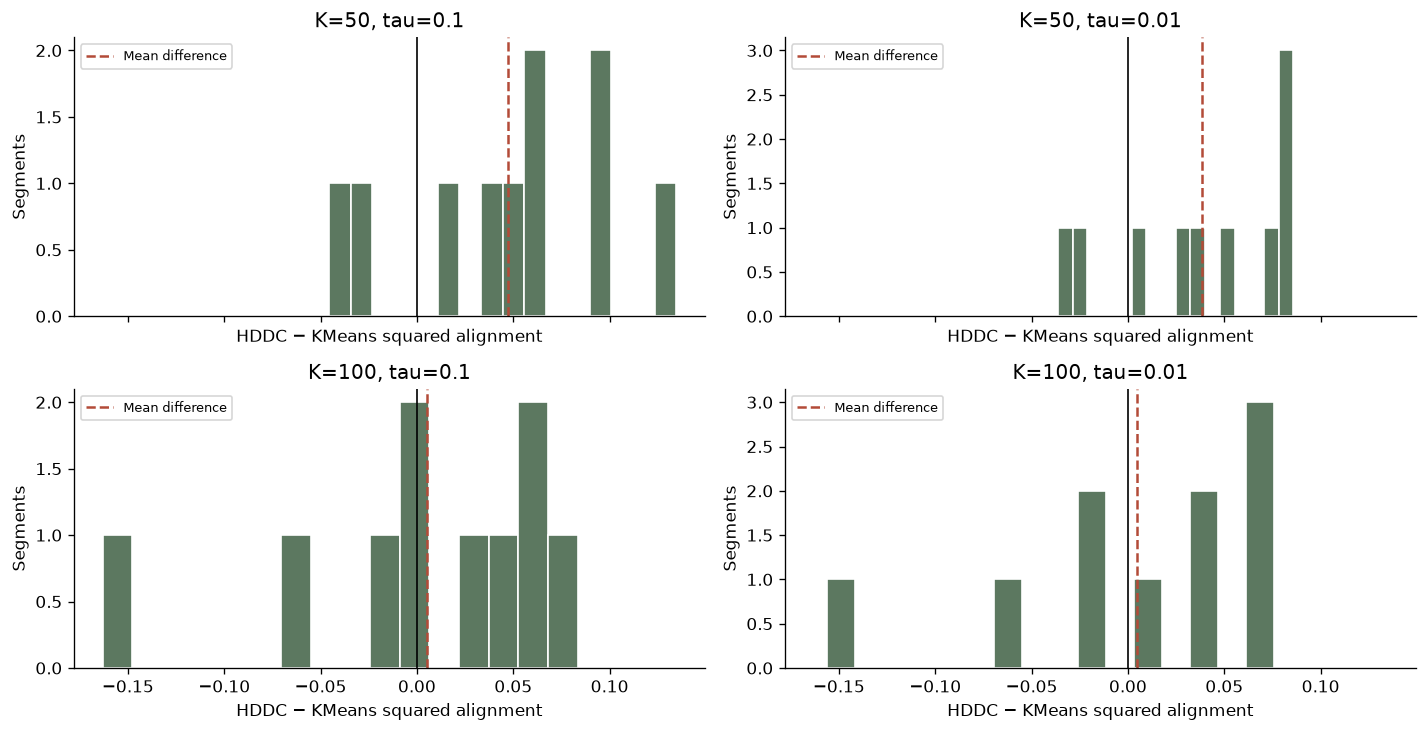

,K,tau,mean_difference,median_difference,hddc_higher_fraction,segments
0,50,0.10,0.047294,0.053361,0.8,10
1,50,0.01,0.038528,0.041788,0.8,10
2,100,0.10,0.005266,0.019697,0.6,10
3,100,0.01,0.004453,0.019021,0.6,10


Artifacts: /orfeo/cephfs/home/dssc/zenocosini/decomposing-activations-local-geometry/outputs/experiments/year_centroid_alignment_original_space/layer04_original_space_block100_centroids_20261111T140211_444543Z
Reference: all-template 100-year block centroids; TEMPLATE_ID is ignored.


In [10]:
fig, axes = plt.subplots(len(K_VALUES), len(TAUS), figsize=(12, 3.1 * len(K_VALUES)),
                         squeeze=False, sharex=True)
paired_rows = []
for i, k in enumerate(K_VALUES):
    for j, tau in enumerate(TAUS):
        table = segments[(segments.K == k) & (segments.tau == tau)]
        ax = axes[i, j]
        ax.hist(table.difference, bins=16, color="#5c7860", edgecolor="white")
        ax.axvline(0, color="black", linewidth=1)
        ax.axvline(table.difference.mean(), color=COLORS["hddc"], linestyle="--", label="Mean difference")
        ax.set(title=f"K={k}, tau={tau:g}", xlabel="HDDC − KMeans squared alignment", ylabel="Segments")
        ax.legend(fontsize=8)
        paired_rows.append(dict(K=k, tau=tau, mean_difference=table.difference.mean(),
                                median_difference=table.difference.median(),
                                hddc_higher_fraction=(table.difference > 1e-12).mean(),
                                segments=len(table)))
fig.tight_layout()
fig.savefig(RUN_DIR / "paired_differences.png", dpi=180)
fig.savefig(RUN_DIR / "paired_differences.pdf")
plt.show()
paired_summary = pd.DataFrame(paired_rows)
paired_summary.to_csv(RUN_DIR / "paired_summary.csv", index=False)
display(paired_summary)
print("Artifacts:", RUN_DIR)
print("Reference: all-template 100-year block centroids; TEMPLATE_ID is ignored.")

## Interactive data, block centroids, Gaussian components, and secants

Use the dropdown to select model, K, and τ. Drag to rotate and scroll to zoom. The legend toggles data, block centroids, and centroid secants. Blue points are block centroids; orange segments connect the centroids used by evaluation. Hover over a centroid for its year range and prompt count. Hover over an ellipsoid or its center for the **component ID** and **alignment**, plus its contribution and assignment mass.

Ellipsoid color and hover alignment show the component's assignment-weighted mean squared alignment:
$A_k=\sum_s w_{s,k}(t_s^\top v_{k,1})^2 / \sum_s w_{s,k}$.
Undefined scores are gray. Scores use secants and **original PC1 directions in the full activation space**. The 3D angles can differ from the angles used to compute these scores.

The ellipsoids are probability regions of the **3D marginal Gaussian**, using projected full covariances. HDDC includes all fitted loadings and noise; KMeans uses the repository's Gaussian approximation from saved cluster PCA, including residual noise. The probability below controls display size only and does not change the evaluation.

**Thin dotted red lines** show each identifiable component's evaluated PC1, passing through its center and ending at the displayed ellipsoid surface. These lines project the original PC1 directions into global PCA3 for display only. Directions with vanishing projections have no visible line; their full-space evaluation is unchanged. Hover for component ID and alignment; toggle **Evaluated PC1** in the legend to hide the lines.

In [11]:
ELLIPSOID_PROBABILITY = 0.50
ELLIPSOID_OPACITY = 0.12

interactive_alignment = make_alignment_figure(
    projected_activations, prompt_table["year"].tolist(), prompt_table["template_id"].tolist(),
    prompt_table["prompt"].tolist(), plot_reference, plot_comparisons,
    probability=ELLIPSOID_PROBABILITY, opacity=ELLIPSOID_OPACITY,
    alignment_space=f"original {EVALUATION_DIMENSION}D")
interactive_path = RUN_DIR / "interactive_alignment_3d.html"
interactive_alignment.write_html(interactive_path, include_plotlyjs=True)
interactive_alignment.show()
print("Standalone interactive plot:", interactive_path)

Standalone interactive plot: /orfeo/cephfs/home/dssc/zenocosini/decomposing-activations-local-geometry/outputs/experiments/year_centroid_alignment_original_space/layer04_original_space_block100_centroids_20261111T140211_444543Z/interactive_alignment_3d.html
